
0: 384x640 3 persons, 2 sports balls, 1 clock, 380.5ms
Speed: 3.2ms preprocess, 380.5ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)


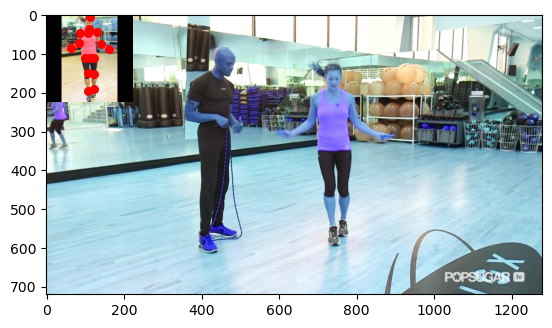

In [1]:
from resizeImage import transform_data
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision.transforms as transforms

class PoseNet(nn.Module):
    def __init__(self):
        super(PoseNet, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 112x112
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 56x56
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 28x28
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 32) 
        )

    def forward(self, x):
        x = self.conv(x)
        x = self.fc(x)
        return x

transform = transforms.Compose([
    transforms.ToTensor(),  # Convert to tensor (3, 224, 224)
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # Normalize RGB
])

In [2]:
image,_ = transform_data('image.png',[])


0: 640x448 1 person, 472.2ms
Speed: 2.0ms preprocess, 472.2ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 448)


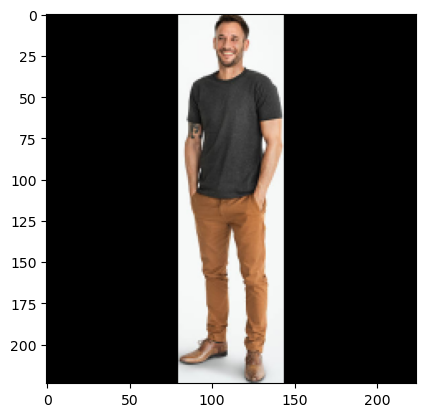

In [3]:
#print the image in plt
plt.imshow(image)



In [8]:
model = PoseNet()
model.load_state_dict(torch.load("posev0402.pth"))
model.eval()
with torch.no_grad():
    img_tensor = transform(image).unsqueeze(0)
    output =model(img_tensor)*224

print(output)


tensor([[117.1734, 189.6040, 111.8813, 143.3567, 112.0657,  94.4093, 133.8359,  99.6564, 142.0012, 149.3861, 153.8177, 202.5354, 124.7932,  99.4273, 120.2648,  44.3554, 118.5801,  40.0922, 118.4037,   6.2697,  93.0061,  59.5175,  91.4458,  61.4150, 107.9039,  45.3598, 133.9046,  45.4840, 142.7400,  59.0182, 144.1688,
          64.9343]])


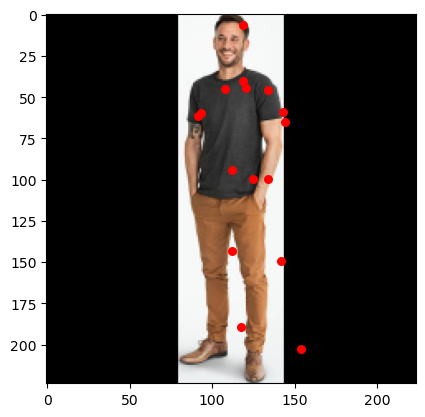

In [9]:
#print the output points in plt
keypoints = output.squeeze()  # Remove extra dimension if necessary
points = [(keypoints[i].item(), keypoints[i+1].item()) for i in range(0, len(keypoints), 2)]
plt.imshow(image)

for (x, y) in points:
    plt.scatter(x, y, color="red", s=30)